# MULTICLASS CLASSIFICATION
## Klasifikasi Jenis Kacang Menggunakan Random Forest

### Deskripsi
Proyek ini bertujuan untuk mengklasifikasikan jenis kacang
berdasarkan karakteristik bentuk dan ukuran menggunakan
algoritma Random Forest Classifier.

Dataset yang digunakan adalah Dry Bean Dataset.

### Tujuan
1. Memahami konsep Multiclass Classification.
2. Melakukan eksplorasi dan preprocessing data.
3. Membuat model Random Forest Classifier.
4. Mengukur performa model menggunakan metrik evaluasi.

### Jenis Klasifikasi
Multiclass Classification dengan 7 kelas:
- BARBUNYA
- BOMBAY
- CALI
- DERMASON
- HOROZ
- SEKER
- SIRA

## 1. Import Library

Mengimpor library yang diperlukan untuk pengolahan data,
visualisasi, pembuatan model Machine Learning,
dan evaluasi hasil klasifikasi.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


## 2. Membaca Dataset

Dataset Dry Bean dibaca menggunakan Pandas.

Dataset ini berisi karakteristik fisik kacang,
seperti luas area, perimeter, panjang sumbu,
lebar sumbu, dan bentuk kacang.

Kolom Class merupakan target yang akan diprediksi.

In [1]:
import pandas as pd

df = pd.read_excel(
    "dataset/Dry_Bean_Dataset.xlsx",
    engine="openpyxl"
)

print("Dataset berhasil dibaca!")
print("Ukuran Dataset:", df.shape)

display(df.head())

Dataset berhasil dibaca!
Ukuran Dataset: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) merupakan proses eksplorasi
data untuk memahami struktur dan karakteristik dataset.

Pada tahap ini dilakukan pemeriksaan tipe data, jumlah baris,
jumlah kolom, serta statistik deskriptif dari setiap fitur.

Tujuannya adalah mengetahui kondisi dataset sebelum
dilakukan proses preprocessing.

In [2]:
print("Informasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: f

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


## 4. Pemeriksaan Missing Value dan Data Duplikat

Pada tahap ini dilakukan pemeriksaan terhadap nilai kosong
(missing value) dan data duplikat.

Pemeriksaan ini bertujuan memastikan dataset memiliki
kualitas yang baik sebelum digunakan untuk training model.

In [3]:
print("Jumlah Missing Value:")
display(df.isnull().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

Jumlah Missing Value:


Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


Jumlah Data Duplikat:
68


## 5. Visualisasi Distribusi Kelas

Visualisasi distribusi kelas digunakan untuk mengetahui
jumlah data pada setiap kategori jenis kacang.

Dataset Dry Bean memiliki tujuh kategori, yaitu BARBUNYA,
BOMBAY, CALI, DERMASON, HOROZ, SEKER, dan SIRA.

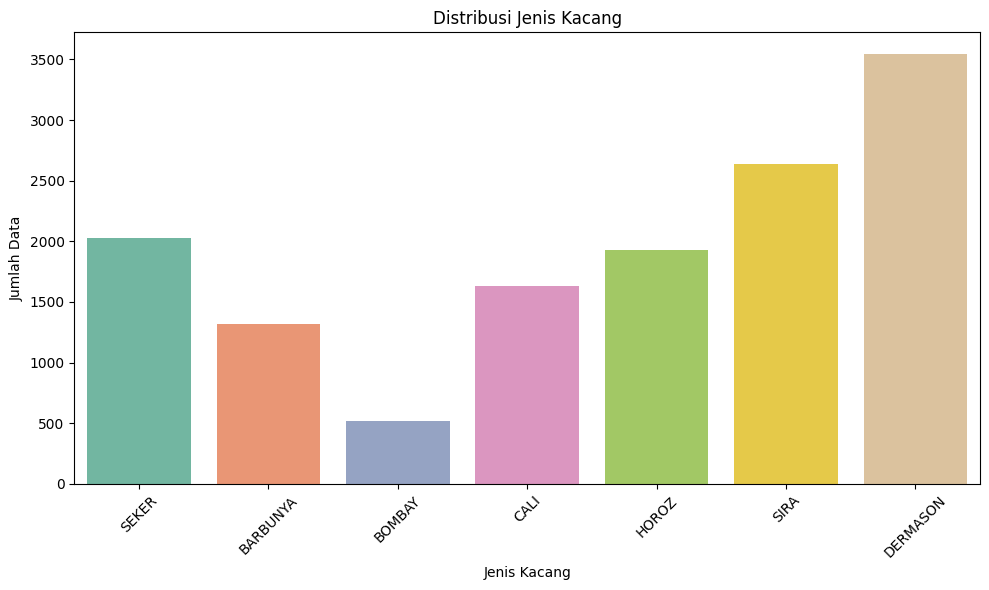

In [6]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    palette="Set2",
    legend=False
)

plt.title("Distribusi Jenis Kacang")
plt.xlabel("Jenis Kacang")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 6. Data Preprocessing

Data preprocessing merupakan proses mempersiapkan dataset
sebelum digunakan dalam Machine Learning.

Pada tahap ini dilakukan penghapusan data duplikat,
pemeriksaan missing value, serta pemisahan fitur
dan target klasifikasi.

In [7]:
# Menghapus data duplikat
df = df.drop_duplicates().copy()

print("Preprocessing Berhasil!")

print("\nUkuran Dataset:")
print(df.shape)

print("\nJumlah Missing Value:")
print(df.isnull().sum().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

Preprocessing Berhasil!

Ukuran Dataset:
(13543, 17)

Jumlah Missing Value:
0

Jumlah Data Duplikat:
0


## 7. Memisahkan Fitur dan Target

Dataset dipisahkan menjadi dua bagian:

- X merupakan fitur karakteristik fisik kacang.
- y merupakan target atau kategori jenis kacang.

Kolom Class digunakan sebagai target yang akan
diprediksi oleh model Random Forest.

In [8]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Jumlah Fitur:", X.shape[1])
print("Jumlah Target:", y.shape[0])

print("\nDaftar Kelas:")
print(sorted(y.unique()))

Jumlah Fitur: 16
Jumlah Target: 13543

Daftar Kelas:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


## 8. Membagi Data Training dan Testing

Dataset dibagi menjadi dua bagian:

- 80% data training untuk melatih model.
- 20% data testing untuk menguji model.

Parameter random_state digunakan agar pembagian data
tetap konsisten.

Stratify digunakan untuk menjaga proporsi setiap kelas.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data Training:", X_train.shape)
print("Data Testing:", X_test.shape)

Data Training: (10834, 16)
Data Testing: (2709, 16)


## 9. Pembuatan Model Random Forest

Random Forest merupakan algoritma Machine Learning
yang menggunakan kumpulan Decision Tree.

Algoritma ini menggabungkan hasil dari beberapa pohon
keputusan untuk menentukan hasil klasifikasi.

Model digunakan untuk memprediksi tujuh jenis kacang
berdasarkan karakteristik fisiknya.

In [10]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Model Random Forest berhasil dibuat!")

Model Random Forest berhasil dibuat!


## 10. Training Model

Training merupakan proses melatih model menggunakan
data training.

Model akan mempelajari pola dari karakteristik fisik
kacang untuk mengenali tujuh kategori jenis kacang.

In [11]:
model.fit(X_train, y_train)

print("Training Model Berhasil!")

Training Model Berhasil!


## 11. Melakukan Prediksi

Setelah model selesai dilatih, tahap selanjutnya adalah
melakukan prediksi menggunakan data testing.

Hasil prediksi akan dibandingkan dengan kategori
sebenarnya untuk mengetahui kemampuan model
dalam mengklasifikasikan jenis kacang.

In [12]:
y_pred = model.predict(X_test)

hasil = pd.DataFrame({
    "Jenis Kacang Aktual": y_test.values,
    "Hasil Prediksi": y_pred
})

display(hasil.head(10))

,Jenis Kacang Aktual,Hasil Prediksi
0,SEKER,SEKER
1,DERMASON,DERMASON
2,DERMASON,DERMASON
3,HOROZ,HOROZ
4,SEKER,SEKER
5,DERMASON,DERMASON
6,DERMASON,DERMASON
7,DERMASON,DERMASON
8,BARBUNYA,BARBUNYA
9,DERMASON,DERMASON


## 12. Evaluasi Model

Evaluasi dilakukan untuk mengukur performa model
dalam mengklasifikasikan tujuh jenis kacang.

Metrik evaluasi yang digunakan:

1. Accuracy: Persentase prediksi yang benar.
2. Precision: Ketepatan hasil prediksi.
3. Recall: Kemampuan menemukan kelas sebenarnya.
4. F1-Score: Gabungan Precision dan Recall.

Average Macro digunakan agar setiap kelas
memiliki bobot penilaian yang sama.

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro"
)

recall = recall_score(
    y_test, y_pred, average="macro"
)

f1 = f1_score(
    y_test, y_pred, average="macro"
)

print("===== HASIL EVALUASI MODEL =====")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

===== HASIL EVALUASI MODEL =====
Accuracy : 91.69 %
Precision: 93.02 %
Recall   : 92.81 %
F1-Score : 92.9 %

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.93      0.92       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.96      0.95       406
        SIRA       0.86      0.85      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



## 13. Confusion Matrix

Confusion Matrix digunakan untuk melihat perbandingan
antara kategori aktual dengan hasil prediksi model.

Matriks ini membantu mengetahui kategori kacang
yang berhasil diprediksi dengan benar maupun
yang masih mengalami kesalahan klasifikasi.

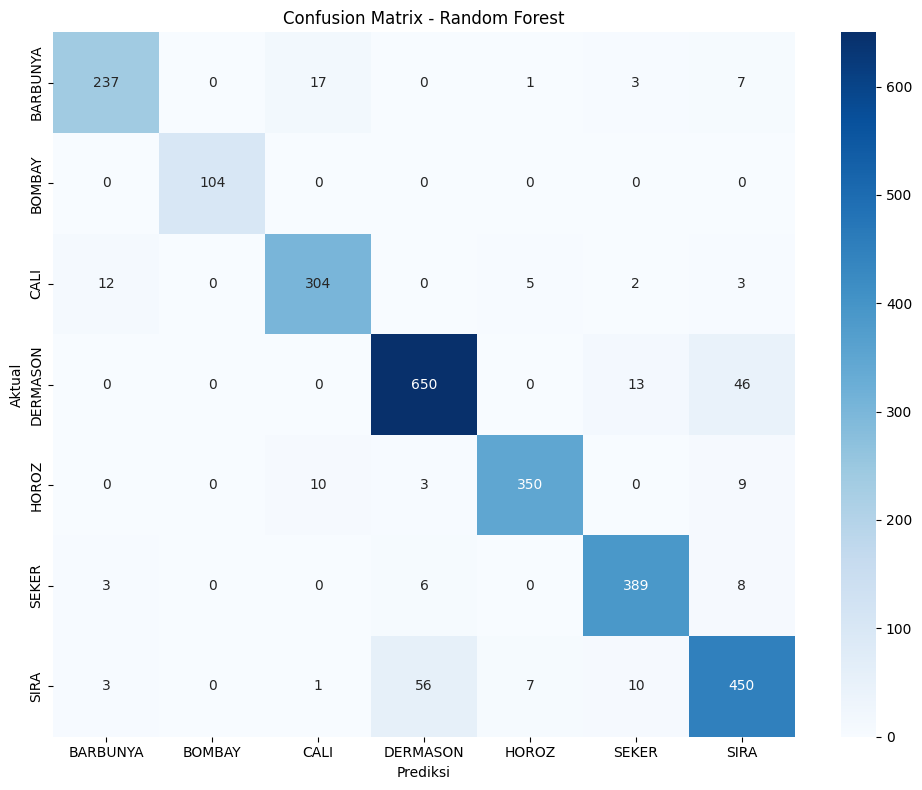

In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.tight_layout()
plt.show()

## 14. Feature Importance

Feature Importance digunakan untuk mengetahui
fitur yang paling berpengaruh dalam proses klasifikasi.

Random Forest menyediakan nilai Feature Importance
untuk menunjukkan kontribusi setiap fitur
dalam menghasilkan prediksi.

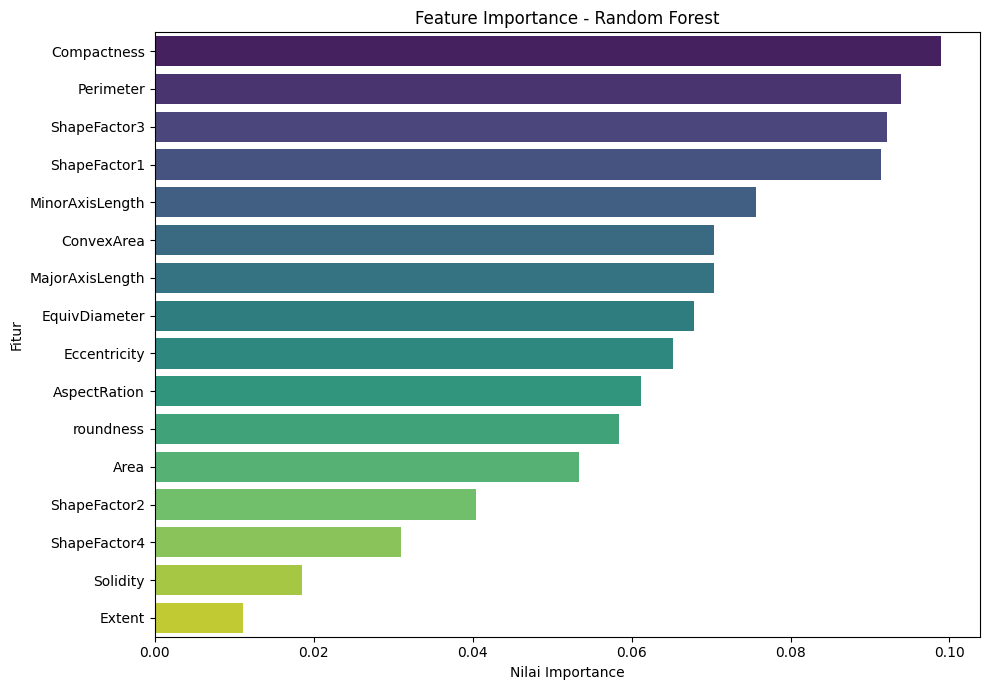

,Fitur,Importance
11,Compactness,0.098900
1,Perimeter,0.093920
14,ShapeFactor3,0.092082
12,ShapeFactor1,0.091376
3,MinorAxisLength,0.075702
6,ConvexArea,0.070428
2,MajorAxisLength,0.070407
7,EquivDiameter,0.067903
5,Eccentricity,0.065256
4,AspectRation,0.061174


In [15]:
importance = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance,
    x="Importance",
    y="Fitur",
    hue="Fitur",
    palette="viridis",
    legend=False
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Nilai Importance")
plt.ylabel("Fitur")

plt.tight_layout()
plt.show()

display(importance)

## 15. Kesimpulan

Berdasarkan proses klasifikasi yang telah dilakukan,
algoritma Random Forest digunakan untuk memprediksi
tujuh jenis kacang berdasarkan karakteristik fisiknya.

Proses penelitian meliputi eksplorasi data,
preprocessing, pembagian data training dan testing,
pelatihan model, serta evaluasi.

Evaluasi menggunakan Accuracy, Precision, Recall,
F1-Score, dan Confusion Matrix.

Hasil evaluasi menunjukkan kemampuan model dalam
membedakan tujuh kategori jenis kacang.

Kesimpulan akhir disesuaikan dengan hasil evaluasi
yang diperoleh setelah program dijalankan.